# Medical Insurance Charges Prediction Using Linear Regression

## Objective

The objective of this analysis is to develop and evaluate a multiple linear regression model for predicting medical insurance charges using the characteristics available in the insurance dataset.

The analysis includes data inspection and cleaning, exploratory data analysis, feature selection, preprocessing, model training and model evaluation. Visualisations are used to identify important patterns in the data, while appropriate regression metrics are used to evaluate the predictive performance of the final model.

In [60]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating visualisations
import matplotlib.pyplot as plt

# Import seaborn for statistical visualisations
import seaborn as sns

In [61]:
# Load the insurance dataset into a pandas DataFrame
df = pd.read_csv("insurance.csv")

# Display the first five rows of the dataset
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [62]:
# Check the number of rows and columns in the dataset
df.shape

(1338, 7)

In [63]:
# Display information about the dataset,
# including column names, data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [64]:
# Check each column for missing values
# Missing values could affect our analysis and model training
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [65]:
# Check whether the dataset contains duplicate rows
# Duplicate records can distort our analysis and model results
df.duplicated().sum()

1

In [66]:
# Generate descriptive statistics for the numerical variables
# This helps us understand the central tendency and spread of the data
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [67]:
# Display the unique categories in each categorical variable
print("Sex:", df["sex"].unique())
print("Smoker:", df["smoker"].unique())
print("Region:", df["region"].unique())

Sex: ['female' 'male']
Smoker: ['yes' 'no']
Region: ['southwest' 'southeast' 'northwest' 'northeast']


In [68]:
# Count the number of observations in each category
print("\nSex distribution:")
print(df["sex"].value_counts())

print("\nSmoker distribution:")
print(df["smoker"].value_counts())

print("\nRegion distribution:")
print(df["region"].value_counts())


Sex distribution:
sex
male      676
female    662
Name: count, dtype: int64

Smoker distribution:
smoker
no     1064
yes     274
Name: count, dtype: int64

Region distribution:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


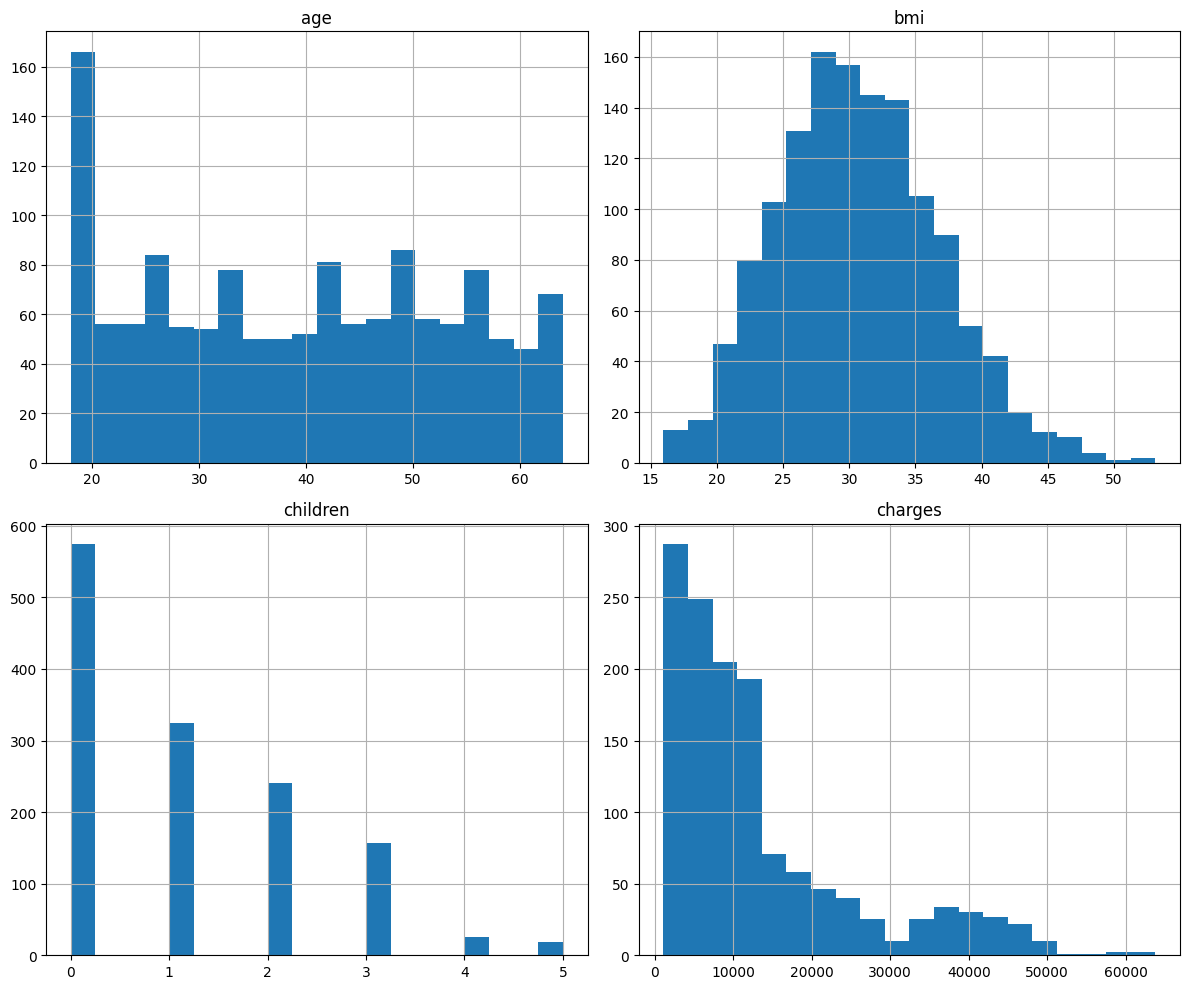

In [69]:
# Plot histograms for the numerical variables.
# Histograms help us understand the distribution and spread of each variable.

df.hist(figsize=(12, 10), bins=20)

# Adjust the layout so that the plots do not overlap
plt.tight_layout()

# Display the plots
plt.show()

Histogram Interpretation:
The histograms show that age is distributed across the dataset with a higher concentration among younger individuals. BMI has an approximately normal distribution, with most observations concentrated around the middle BMI range. The number of children is positively skewed, with most individuals having few or no children. Medical charges are strongly right-skewed, indicating that most individuals incur relatively low medical costs while a smaller proportion experience substantially higher charges. The skewness in medical charges may influence the performance of the linear regression model and should therefore be considered during model evaluation.

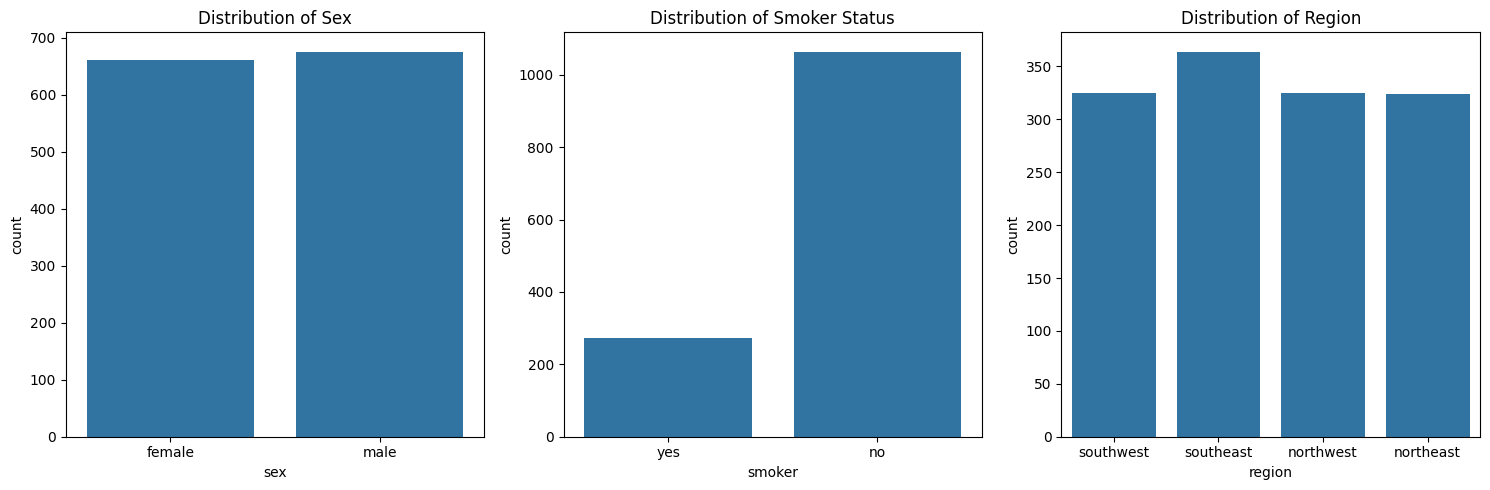

In [70]:
# Create count plots for the categorical variables.
# These plots show how many observations fall into each category.

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.countplot(data=df, x="sex", ax=axes[0])
axes[0].set_title("Distribution of Sex")

sns.countplot(data=df, x="smoker", ax=axes[1])
axes[1].set_title("Distribution of Smoker Status")

sns.countplot(data=df, x="region", ax=axes[2])
axes[2].set_title("Distribution of Region")

plt.tight_layout()
plt.show()

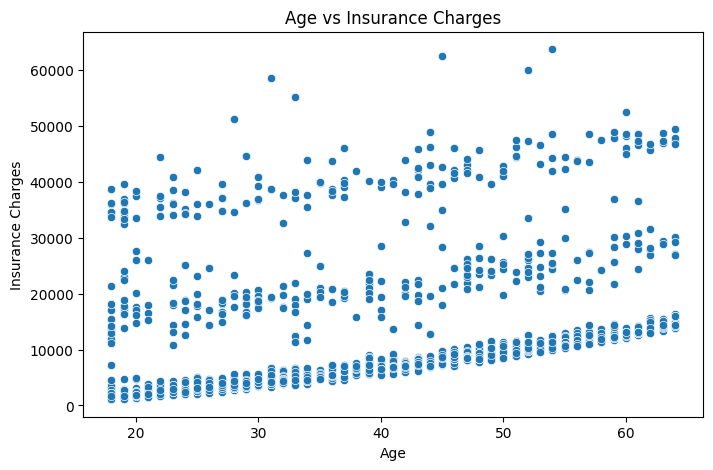

In [71]:
# Examine the relationship between age and insurance charges.
# A scatter plot allows us to see whether charges tend to increase
# or decrease as age increases.

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="age", y="charges")

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")

plt.show()

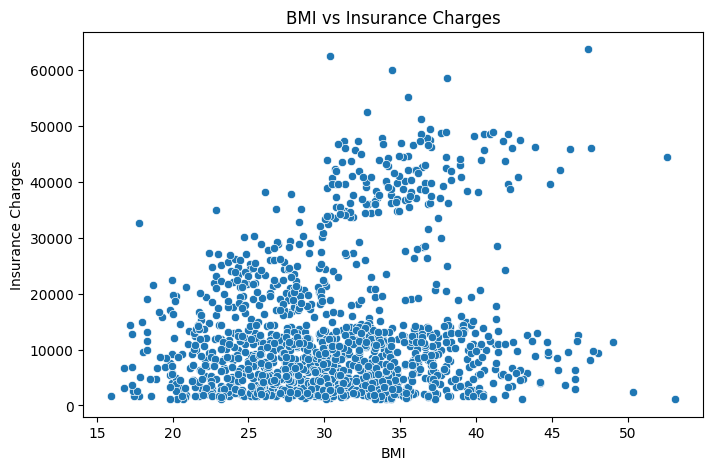

In [72]:
# Examine the relationship between BMI and insurance charges.

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="bmi", y="charges")

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")

plt.show()

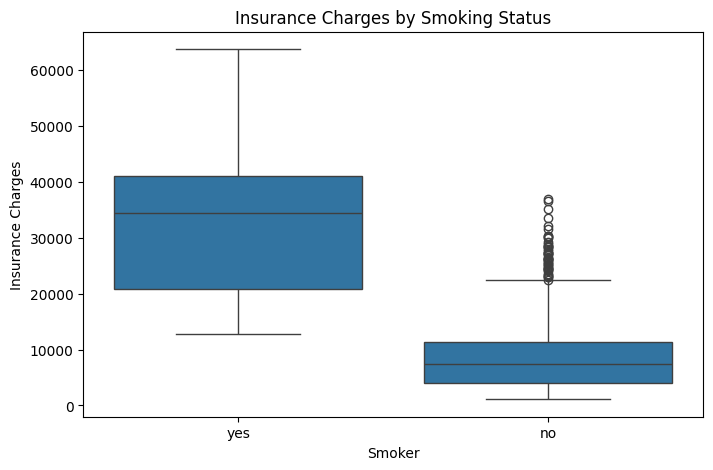

In [73]:
# Compare insurance charges between smokers and non-smokers.
# A boxplot helps us compare the distribution of charges across the two groups.

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")

plt.show()

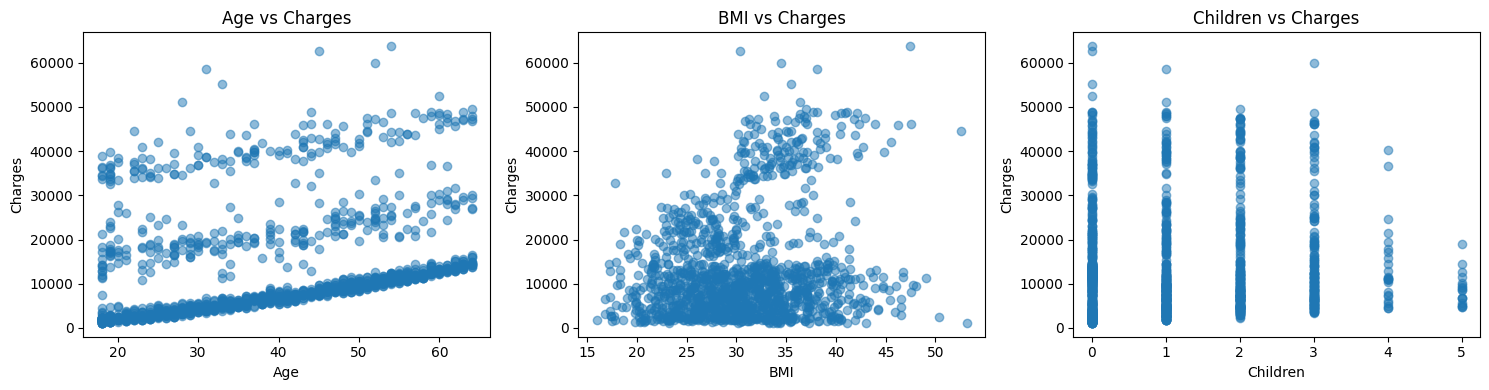

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(df['age'], df['charges'], alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Charges')
plt.title('Age vs Charges')

plt.subplot(1, 3, 2)
plt.scatter(df['bmi'], df['charges'], alpha=0.5)
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.title('BMI vs Charges')

plt.subplot(1, 3, 3)
plt.scatter(df['children'], df['charges'], alpha=0.5)
plt.xlabel('Children')
plt.ylabel('Charges')
plt.title('Children vs Charges')

plt.tight_layout()
plt.show()

Scatter Plot Interpretation:
The scatter plots indicate that age has a positive relationship with medical charges, with charges generally increasing as age increases. BMI shows a less distinct relationship with charges, although substantially higher charges are observed among some individuals with higher BMI values. The number of children does not display a strong linear relationship with medical charges, as charges vary considerably across the different categories. The presence of distinct groups of observations, particularly in the age and BMI plots, suggests that additional variables may influence medical charges.

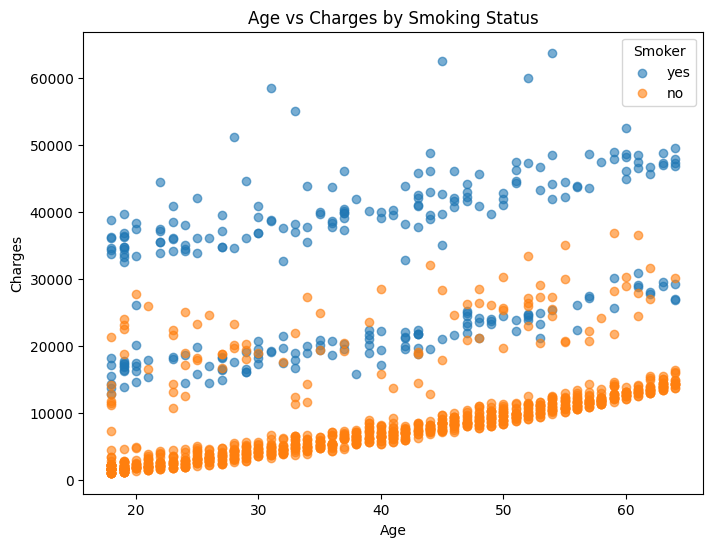

In [75]:
plt.figure(figsize=(8, 6))

for status in df['smoker'].unique():
    subset = df[df['smoker'] == status]
    plt.scatter(
        subset['age'],
        subset['charges'],
        alpha=0.6,
        label=status
    )

plt.xlabel('Age')
plt.ylabel('Charges')
plt.title('Age vs Charges by Smoking Status')
plt.legend(title='Smoker')
plt.show()

Smoking Status Interpretation:
The scatter plot demonstrates a clear difference in medical charges between smokers and non-smokers. Smokers generally incur substantially higher medical charges than non-smokers across different age groups. Although charges tend to increase with age for both groups, smoking status appears to be an important factor associated with higher medical costs. This suggests that smoking status is likely to be a significant predictor in the linear regression model.

## Correlation Analysis

Correlation analysis is performed to measure the strength and direction of the linear relationship between the numerical variables in the dataset.

The correlation coefficient ranges from -1 to +1:
- A value close to +1 indicates a strong positive relationship.
- A value close to -1 indicates a strong negative relationship.
- A value close to 0 indicates little or no linear relationship.

In this analysis, the correlation between age, BMI, number of children and medical charges will be examined. This will help identify which numerical variables may be useful predictors of medical charges in the linear regression model.

In [76]:
# Select the numerical variables
numeric_df = df[['age', 'bmi', 'children', 'charges']]

# Calculate the correlation coefficients
correlation_matrix = numeric_df.corr()

# Display the correlation matrix
print(correlation_matrix)

               age       bmi  children   charges
age       1.000000  0.109272  0.042469  0.299008
bmi       0.109272  1.000000  0.012759  0.198341
children  0.042469  0.012759  1.000000  0.067998
charges   0.299008  0.198341  0.067998  1.000000


### Correlation Heatmap

A heatmap is used to visually represent the correlation coefficients. The annotated values make it easier to compare the strength and direction of the relationships between the numerical variables.

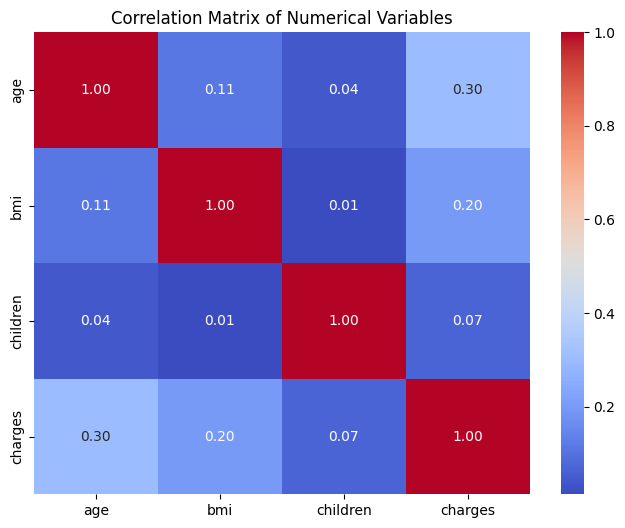

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Variables')
plt.show()

### Interpretation of the Correlation Analysis

The correlation matrix shows that age has the strongest positive linear relationship with medical charges among the numerical predictor variables, with a correlation coefficient of 0.30. This indicates that medical charges generally tend to increase as age increases, although the relationship is not particularly strong.

BMI has a weaker positive correlation of 0.20 with medical charges, suggesting that higher BMI values are associated with somewhat higher medical costs. The number of children has a very weak positive correlation with charges (0.07), indicating little linear relationship between these two variables.

The numerical predictor variables also show relatively low correlations with one another. Overall, age appears to be the most influential numerical predictor of medical charges based on correlation alone. However, the earlier visual analysis indicated that categorical variables, particularly smoking status, may also have an important relationship with medical charges. These categorical variables will therefore be included during the preparation of the data for the regression model.

## Feature Selection

Feature selection was informed by the exploratory data analysis, correlation analysis and the relevance of the available variables to the prediction of medical charges.

Among the numerical variables, age showed the strongest correlation with charges (0.30), followed by BMI (0.20), while the number of children showed a weaker correlation (0.07). Although the correlations were not particularly strong, these variables were retained because they may contribute useful predictive information when considered together in a multiple linear regression model.

The exploratory analysis also demonstrated a clear difference in medical charges between smokers and non-smokers, indicating that smoking status may be an important predictor. Sex and region were also retained to allow the model to determine whether these characteristics contribute additional predictive information.

Therefore, age, BMI, children, sex, smoking status and region were selected as predictor variables, while charges was selected as the target variable.

## Data Preprocessing

Before training the linear regression model, the dataset must be prepared so that all predictor variables are in a suitable numerical format.

The dataset contains categorical variables such as sex, smoker and region. Since a linear regression model requires numerical input, these categorical variables need to be converted into numerical representations.

One-hot encoding will be used to transform the categorical variables into binary dummy variables. The `drop_first=True` option is used to remove one category from each categorical variable, which avoids unnecessary redundancy among the encoded variables.

In [78]:
# Convert categorical variables into numerical dummy variables
df_encoded = pd.get_dummies(
    df,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

# Display the first five rows of the encoded dataset
df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


### Encoded Dataset

After one-hot encoding, the categorical variables have been converted into binary variables represented by 0 and 1. This allows the categorical information to be included as predictors in the linear regression model.

In [79]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1338 non-null   int64  
 1   bmi               1338 non-null   float64
 2   children          1338 non-null   int64  
 3   charges           1338 non-null   float64
 4   sex_male          1338 non-null   int32  
 5   smoker_yes        1338 non-null   int32  
 6   region_northwest  1338 non-null   int32  
 7   region_southeast  1338 non-null   int32  
 8   region_southwest  1338 non-null   int32  
dtypes: float64(2), int32(5), int64(2)
memory usage: 68.1 KB


## Feature and Target Variable Selection

The next step is to separate the dataset into predictor variables (features) and the target variable.

The target variable is `charges`, as the objective of the model is to predict medical insurance charges. All remaining encoded variables will be used as features to help predict these charges.

The predictor variables are represented by `X`, while the target variable is represented by `y`.

In [80]:
# Define the predictor variables
X = df_encoded.drop('charges', axis=1)

# Define the target variable
y = df_encoded['charges']

# Display the shapes of X and y
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1338, 8)
y shape: (1338,)


## Training and Testing Data

The dataset is divided into training and testing sets before building the linear regression model.

The training data is used to train the model and allow it to learn the relationship between the predictor variables and medical charges. The testing data is kept separate and is used to evaluate how well the trained model performs on unseen observations.

An 80/20 split is used, where 80% of the observations are used for training and 20% are used for testing. A `random_state` of 42 is specified to ensure that the same split can be reproduced each time the code is executed.

In [81]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1070, 8)
Testing features: (268, 8)
Training target: (1070,)
Testing target: (268,)


## Linear Regression Model Training

A multiple linear regression model is used because the analysis includes several predictor variables that may influence medical insurance charges.

The model is trained using the training dataset. During training, the algorithm estimates the relationship between each predictor variable and the target variable, `charges`.

Once trained, the model can be used to predict medical charges for observations in the testing dataset.

In [82]:
from sklearn.linear_model import LinearRegression

# Create the linear regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [83]:
# Make predictions using the testing data
y_pred = model.predict(X_test)

# Compare the first five actual and predicted charges
comparison = pd.DataFrame({
    'Actual Charges': y_test.values,
    'Predicted Charges': y_pred
})

comparison.head()

,Actual Charges,Predicted Charges
0,9095.06825,8969.550274
1,5272.17580,7068.747443
2,29330.98315,36858.410912
3,9301.89355,9454.678501
4,33750.29180,26973.173457


### Initial Comparison of Actual and Predicted Charges

The first five predictions demonstrate that the linear regression model is able to generate estimated medical charges for previously unseen observations. Some predicted values are relatively close to the actual charges, while others show larger differences.

However, a small number of observations is not sufficient to determine the overall performance of the model. Therefore, formal regression evaluation metrics will be calculated to assess the accuracy and explanatory power of the model across the complete testing dataset.

## Model Evaluation

The performance of the linear regression model is evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

- **MAE** measures the average absolute difference between the actual and predicted charges.
- **MSE** measures the average squared prediction error and gives greater weight to larger errors.
- **RMSE** represents the typical prediction error in the same units as medical charges.
- **R²** measures the proportion of variation in medical charges that is explained by the regression model. An R² value closer to 1 indicates greater explanatory power.

### Selection and Justification of Evaluation Metrics

MAE, RMSE and R² were selected to evaluate the linear regression model because they provide complementary information about model performance.

MAE was selected because it provides an easily interpretable measure of the average prediction error in the same units as medical charges. RMSE was selected because it gives greater weight to larger prediction errors, making it useful for identifying whether substantial prediction errors are present. R² was selected to measure the proportion of variation in medical charges explained by the predictor variables.

MSE is also reported as the underlying squared-error measure used to calculate RMSE, although RMSE is easier to interpret because it is expressed in the same units as the target variable.

In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate model evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the results
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

Mean Absolute Error (MAE): 4181.19
Mean Squared Error (MSE): 33596915.85
Root Mean Squared Error (RMSE): 5796.28
R-squared (R²): 0.7836


### Interpretation of Model Performance

The linear regression model achieved an R² value of 0.7836. This indicates that approximately 78.36% of the variation in medical insurance charges is explained by the predictor variables included in the model. The remaining 21.64% of the variation may be associated with factors not included in the dataset, random variation, or relationships that are not fully captured by a linear model.

The Mean Absolute Error (MAE) is 4,181.19, meaning that the model's predictions differ from the actual medical charges by approximately 4,181 units on average.

The Root Mean Squared Error (RMSE) is 5,796.28. Since RMSE gives greater weight to larger prediction errors, its higher value compared with MAE suggests that some observations have relatively large prediction errors.

The Mean Squared Error (MSE) is 33,596,915.85. This value is relatively large because the prediction errors are squared and therefore it is less directly interpretable in the original units than MAE and RMSE.

Overall, the results indicate that the multiple linear regression model explains a substantial proportion of the variation in medical insurance charges, although prediction errors remain for some observations.

## Actual vs Predicted Medical Charges

To visually assess the performance of the regression model, the actual medical charges are compared with the charges predicted by the model.

If the model predicts perfectly, the observations would lie directly along the diagonal reference line. Points further away from this line represent larger prediction errors.

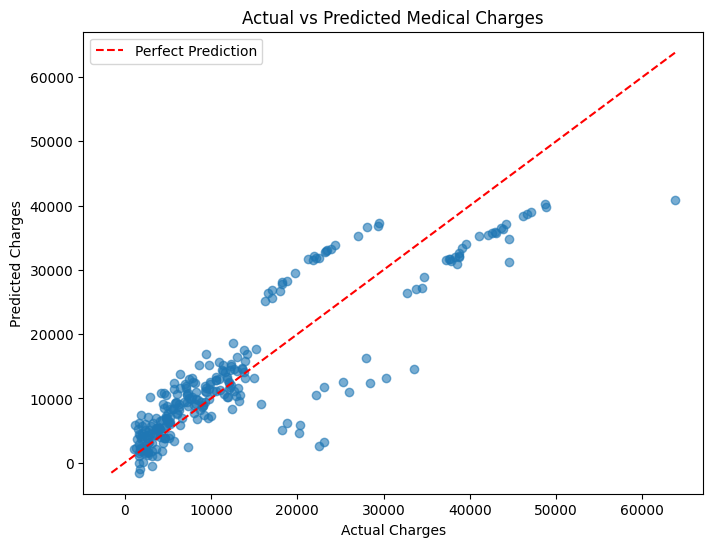

In [85]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Create a diagonal reference line representing perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Medical Charges')
plt.legend()
plt.show()

### Interpretation of Actual vs Predicted Charges

The actual versus predicted charges plot provides a visual assessment of the performance of the linear regression model. The diagonal reference line represents perfect predictions, where the predicted charge would be equal to the actual charge.

Many observations, particularly among the lower medical charges, are located relatively close to the reference line, indicating that the model produces reasonably accurate predictions for these cases. However, several observations are positioned further away from the line, particularly among some of the higher medical charges. This indicates that the model overestimates or underestimates charges for certain individuals.

The visible prediction errors are consistent with the MAE and RMSE results. Overall, the plot supports the R² result of 0.7836, showing that the model explains a substantial proportion of the variation in medical charges but does not perfectly predict every observation.

## Regression Coefficients

The coefficients of the multiple linear regression model are examined to understand the estimated relationship between each predictor variable and medical charges.

A positive coefficient indicates that an increase in the predictor is associated with an increase in predicted charges, while a negative coefficient indicates an association with lower predicted charges, holding the other variables constant.

For dummy variables, the coefficient represents the estimated difference relative to the reference category that was removed during one-hot encoding.

In [86]:
# Create a table containing the regression coefficients
coefficients = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient': model.coef_
})

# Sort from largest to smallest coefficient
coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

coefficients

,Variable,Coefficient
4,smoker_yes,23651.128856
2,children,425.278784
1,bmi,337.092552
0,age,256.975706
3,sex_male,-18.591692
5,region_northwest,-370.677326
6,region_southeast,-657.864297
7,region_southwest,-809.799354


In [87]:
print(f"Model Intercept: {model.intercept_:.2f}")

Model Intercept: -11931.22


### Interpretation of Regression Coefficients

The regression coefficients indicate the estimated change in predicted medical charges associated with each predictor while holding the other variables constant.

Smoking status has a particularly large coefficient. The coefficient for `smoker_yes` is approximately 23,651.13, indicating that smokers are predicted to incur approximately 23,651 more in medical charges than non-smokers, after controlling for the other variables in the model. This supports the pattern observed earlier in the smoking-status scatter plot.

Age has a positive coefficient of approximately 256.98, indicating that each additional year of age is associated with an increase of approximately 256.98 in predicted medical charges, holding the other variables constant.

BMI has a positive coefficient of approximately 337.09, meaning that a one-unit increase in BMI is associated with an increase of approximately 337.09 in predicted charges. The coefficient for children is approximately 425.28, suggesting that each additional child is associated with an increase of approximately 425.28 in predicted charges.

The coefficient for `sex_male` is approximately -18.59, indicating only a small estimated difference between males and the reference category, females, after accounting for the other predictors.

The regional variables have negative coefficients relative to the reference region, which is `region_northeast`. The coefficients are approximately -370.68 for northwest, -657.86 for southeast and -809.80 for southwest.

Overall, the fitted model shows that smoking status is associated with a particularly large difference in predicted medical charges. However, the absolute sizes of coefficients should not automatically be interpreted as measures of variable importance because the predictor variables are measured on different scales.

The model intercept is -11,931.22. However, the intercept has limited practical interpretation because it represents predicted charges when numerical predictors such as age and BMI are equal to zero, which falls outside the observed and meaningful range of the dataset.

## Conclusion

This analysis developed a multiple linear regression model to predict medical insurance charges using demographic and lifestyle-related variables.

Exploratory Data Analysis (EDA) was first conducted to understand the structure and distribution of the data. The analysis showed that medical charges were positively skewed, with most individuals having relatively lower charges and a smaller number experiencing substantially higher costs. Scatter plots indicated that age had a positive relationship with medical charges, while BMI showed a weaker relationship and the number of children showed little clear linear relationship with charges.

Smoking status emerged as an important factor during the exploratory analysis. Smokers generally displayed substantially higher medical charges than non-smokers across different age groups. Correlation analysis further showed that age had the strongest positive correlation with charges among the numerical predictors (0.30), followed by BMI (0.20) and children (0.07).

The categorical variables were converted into numerical dummy variables using one-hot encoding, after which the data was divided into 80% training data and 20% testing data. A multiple linear regression model was then trained using the selected predictor variables.

The model achieved an R² value of 0.7836, indicating that approximately 78.36% of the variation in medical insurance charges was explained by the predictors included in the model. The model produced a Mean Absolute Error (MAE) of 4,181.19 and a Root Mean Squared Error (RMSE) of 5,796.28. The higher RMSE compared with MAE indicates that some observations had relatively large prediction errors.

Analysis of the regression coefficients showed that smoking status was associated with a particularly large difference in predicted medical charges. The coefficient for smokers was approximately 23,651.13, indicating substantially higher predicted charges for smokers compared with non-smokers when the other variables were held constant. Age, BMI and number of children also had positive coefficients.

Overall, the multiple linear regression model demonstrated useful predictive and explanatory performance on the test dataset. However, the model does not explain all variation in medical charges and larger prediction errors remain for some observations. The results demonstrate how exploratory data analysis, feature selection, data preprocessing, model training and evaluation can be combined to develop a data-driven model for estimating medical insurance costs.

## Limitations

Although the model explains a substantial proportion of the variation in medical charges, several limitations should be considered. The dataset contains a limited number of demographic and lifestyle variables, and other factors that may influence healthcare costs are not represented. In addition, linear regression assumes that relationships between the predictors and target variable can be adequately represented using a linear model.

The analysis therefore demonstrates predictive relationships within the available dataset and should not be interpreted as establishing causal relationships between the predictor variables and medical charges.